# V04: OCI service private endpoint

Query a private database through default private DNS proxy resolution without adding a test-specific Advanced DNS entry.

[Choose another use case](README.md). This notebook is an unexecuted sample, not a live validation report.


## DNS resolution path

Advanced DNS explicit entries and default private DNS proxy resolution serve different purposes. Determine the hostname's resolution path before editing the workspace.

| Mechanism | Resolution and traffic behavior | What to configure or verify |
| --- | --- | --- |
| Explicit Advanced DNS entry | Provisioning resolves the supplied public hostname from the service environment and installs an explicit mapping. The runtime DNS answer directs application traffic through the workspace private connection into the customer VCN. | Use a service-resolvable hostname requiring customer-network routing, then verify provisioning, saved state, workload DNS and the authenticated operation. A customer-VM lookup alone does not establish service-side resolvability. |
| Default private DNS proxy path | A private ADB hostname that the service resolver cannot resolve is handled through the private-endpoint DNS proxy and customer DNS context. | Verify customer DNS, private routes, listener security and the private descriptor. Do not add the private hostname solely because it is private. |
| Regional service-zone allowance | A regional service-domain policy permits covered zones in the applicable context. | Verify the deployment's eligibility and endpoint. This is neither an automatically inserted workspace entry nor proof that the private DNS proxy supplied the answer. |

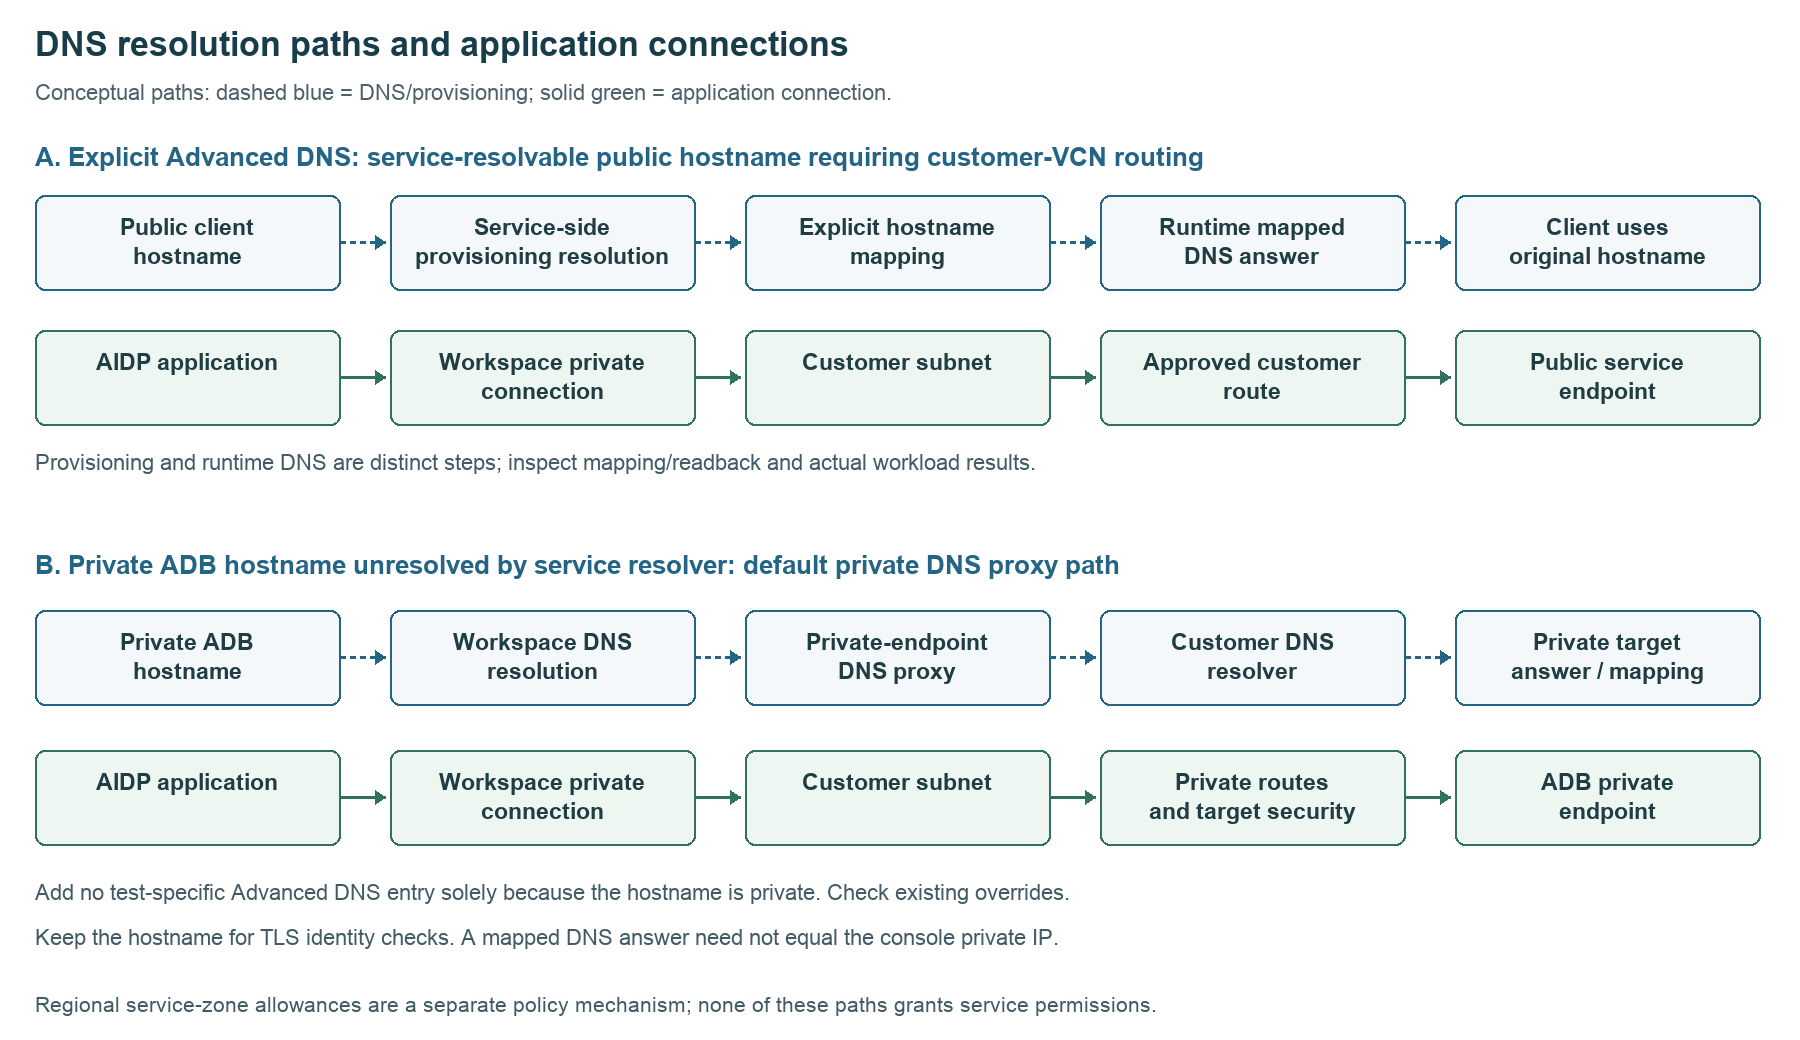

Dashed blue arrows describe DNS/provisioning relationships; solid green arrows show application connections. The diagram is conceptual, not a packet trace. An address returned inside AIDP can be a service-managed mapping and need not equal the private address in the destination console. Keep using the original hostname for TLS server identity checks.

**Before testing:** record the complete DNS/SCAN list, endpoint type, existing overrides and effective client configuration. A successful query alone does not identify the resolution mechanism. Do not delete a shared override to create a clean baseline. Use an approved clean test workspace or mark the default-path claim **INCOMPLETE** when provenance cannot be established.

For V04, first test the private endpoint without adding a test-specific Advanced DNS entry. For V01–V03, V06 and V07, explicit-entry tests require service-resolvable hostnames; private-only names are unsuitable for demonstrating that provisioning mechanism. An unresolved owned name can remain a deliberately negative V06 test.

The [public workspace guide](https://docs.oracle.com/en/cloud/paas/ai-data-platform/aidug/workspaces.html) lists broad private-network scenarios; endpoint type and deployed resolver behavior determine whether an explicit entry is necessary. The [ADB private endpoint guide](https://docs.oracle.com/en/cloud/paas/autonomous-database/serverless/adbsb/private-endpoints-autonomous.html) describes the destination's private access setup. Confirm your deployment's behavior with the administrator and retain independent evidence for the resolution path you claim.


## Network setup

Complete and verify these prerequisites with your network/service administrator before the workload comparison. The notebook does not create routes, change policies, configure DNS, or start compute.

| Area | Required setup and verification |
| --- | --- |
| Destination | Select an existing Autonomous Database private endpoint. Copy its private connection descriptor, hostname, listener port and service name from Database Connection. A regional public hostname protected by an ACL is a different case. |
| Workspace and routing | Attach the workspace to the required customer private network. Verify the destination subnet route and return path. For a different VCN, arrange supported local/remote peering or DRG connectivity with non-overlapping ranges and the appropriate route tables. |
| DNS | For a private ADB hostname that the service resolver cannot resolve, use default private-endpoint DNS proxy resolution through customer DNS. Do not add an Advanced DNS entry solely because the hostname is private. Verify runtime resolution reaches the intended target. Configure customer resolver/forwarding rules if your topology needs them. Stop on a private/split-DNS mismatch; do not substitute a public descriptor to pass the case. |
| Security | Allow the actual listener port through the relevant subnet/NSG/firewall rules and target access configuration, including any service-required workspace rules. NAT/internet routing is not needed for the illustrated private destination path. |
| Authentication | Prefer an existing workspace external catalog connection, or provide an existing supported wallet ZIP/TNS plus a private runtime secret. Preserve certificate/server identity checks. A wallet-configured query or port 1522 alone does not prove client-certificate presentation. |


### Example network topology

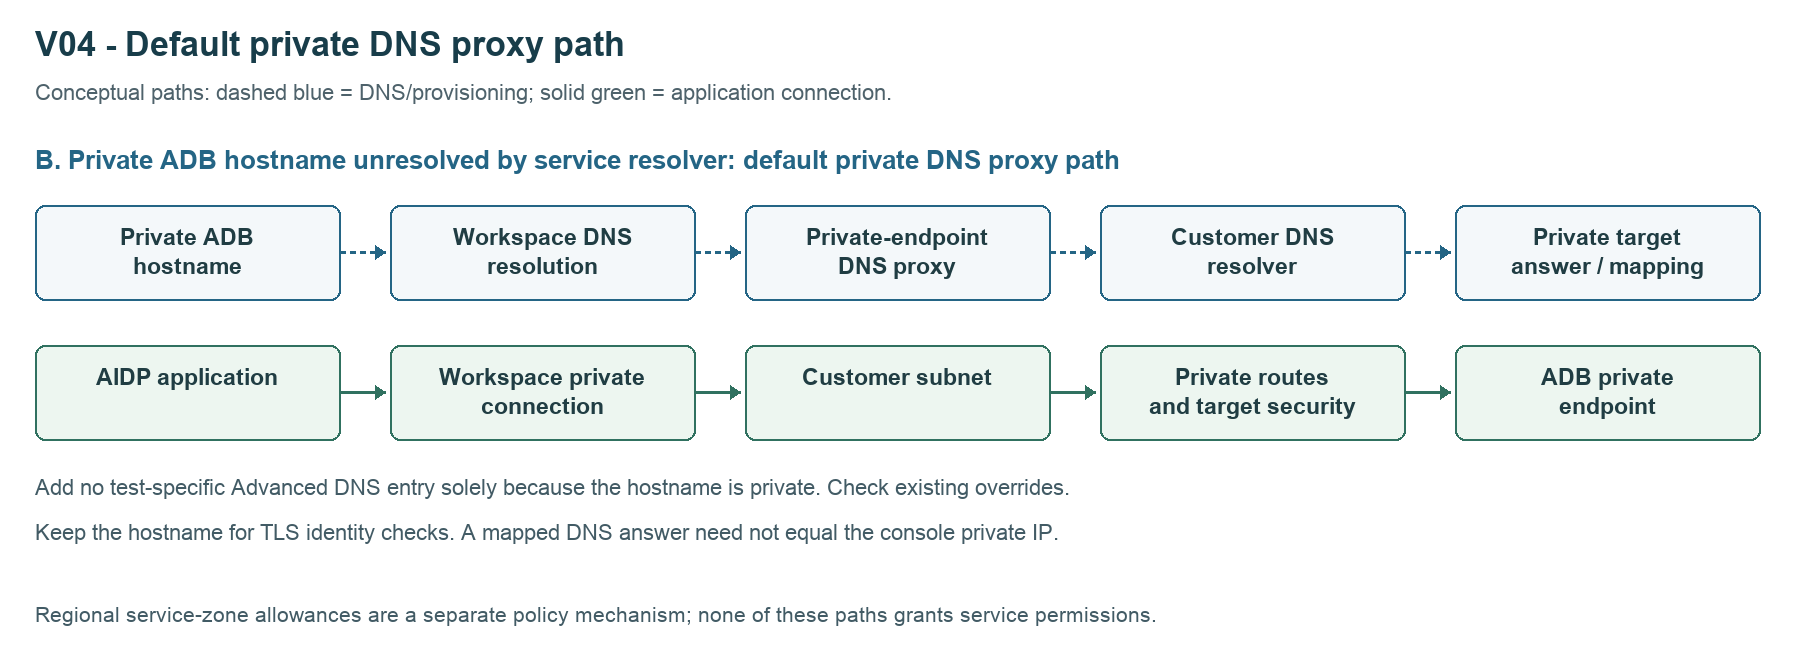

The diagram is illustrative; it does not prove the route taken by a request.


## IAM and network examples

Preparation templates only: replace every angle-bracket placeholder privately. An administrator prepares the approved resources; this notebook applies no policies or network changes.

### Separate operator, service and runtime permissions

The workspace operator needs access to the existing AIDP instance and the appropriate Workbench role/permissions to edit that workspace. Example OCI policies for an identity-domain group are:

```text
Allow group <IDENTITY_DOMAIN>/<WORKSPACE_OPERATORS> to use ai-data-platforms in compartment <AIDP_COMPARTMENT>
Allow group <IDENTITY_DOMAIN>/<WORKSPACE_OPERATORS> to inspect vcns in compartment <VCN_COMPARTMENT>
Allow group <IDENTITY_DOMAIN>/<WORKSPACE_OPERATORS> to inspect subnets in compartment <SUBNET_COMPARTMENT>
Allow group <IDENTITY_DOMAIN>/<WORKSPACE_OPERATORS> to inspect network-security-groups in compartment <NSG_COMPARTMENT>
```

These statements allow instance access and network selection; they do not grant Workbench workspace-edit privileges, create infrastructure or authorize reads from data sources. Use the existing approved Workbench role. Policies belong in the relevant compartment or an ancestor with authority over that scope.

The platform also needs its private-network service permissions. The following adapts the documented AIDP network statements to explicit resource compartments and one instance:

```text
Allow any-user to manage vnics in compartment <VNIC_COMPARTMENT> where all {request.principal.type='<AIDP_PRINCIPAL_TYPE>', request.principal.id='<AIDP_INSTANCE_ID>'}
Allow any-user to use subnets in compartment <SUBNET_COMPARTMENT> where all {request.principal.type='<AIDP_PRINCIPAL_TYPE>', request.principal.id='<AIDP_INSTANCE_ID>'}
Allow any-user to use network-security-groups in compartment <NSG_COMPARTMENT> where all {request.principal.type='<AIDP_PRINCIPAL_TYPE>', request.principal.id='<AIDP_INSTANCE_ID>'}
```

Select the actual instance principal type (`aidataplatform` or the applicable legacy type), instance ID and placement compartments with your administrator. Retain the other existing service setup policies; this is not a full tenancy bootstrap. The runtime reading data can use a different identity from the operator or AIDP service: establish the connector's effective signer before choosing its policy subject.

Sources: [AIDP IAM policies](https://docs.oracle.com/en/cloud/paas/ai-data-platform/aidug/iam-policies-oracle-ai-data-platform.html), [AIDP workspaces](https://docs.oracle.com/en/cloud/paas/ai-data-platform/aidug/workspaces.html), [IAM policy scope](https://docs.oracle.com/en-us/iaas/Content/Security/Reference/iam_security_topic-IAM_Security_Policies.htm).

### Platform network baseline

The current workspace guide requires ingress from the customer VCN address range to all destination ports for private-network data access. An example baseline rule is **ingress; source CIDR `<CUSTOMER_VCN_CIDR>`; all protocols/ports; stateful**, in the security control selected for that workspace topology. Have the administrator reconcile this platform prerequisite with the approved design. The target-specific examples below are additional destination controls, not a replacement for platform rules. Do not use an internet-wide ingress rule.

Retain working DNS resolver access. With custom resolvers, permit UDP and TCP 53 to the approved resolver and configure forwarding/resolution in the customer network. Explicit Advanced DNS provisioning requires service-side resolvability; a successful customer-only lookup does not establish that prerequisite. Private ADB names unresolved by the service resolver use the default private DNS proxy/customer resolver path. Do not add them solely because they are private. Advanced DNS does not create a customer DNS zone, resolver endpoint, route, NAT gateway, service gateway or database listener. Use stateful connection rules in these examples; stateless designs need explicit return rules. Security lists and NSGs are additive, so check all applicable rules.

Source: [OCI security rules](https://docs.oracle.com/en-us/iaas/Content/Network/Concepts/securityrules.htm).

### Authorization example

The notebook's database identity query uses the existing database login/catalog credentials. OCI `manage autonomous-databases` is a control-plane permission, not permission to query database data. Reuse the existing approved login. If an administrator has already created a dedicated test database user, the connection privilege example is:

```sql
GRANT CREATE SESSION TO <TEST_DB_USER>;
```

The sample query reads `SYS_CONTEXT('USERENV','INSTANCE_NAME') FROM dual`; it does not need grants on application tables or catalog-wide dictionary access. An additional application-table test would need its own object grant. Existing AIDP catalog access must also be granted through Workbench. Wallet access, secret retrieval and IAM database authentication, if selected, have separate prerequisites; this SQL example does not configure them. Preserve TLS/mTLS and server identity checks.

### Route, resolver and NSG examples

| Control | Example |
| --- | --- |
| Same customer VCN | Existing local private routing to the service private endpoint; no NAT or internet gateway for that path. |
| Other VCN | Route `<DATABASE_SUBNET_CIDR>` to the approved LPG/DRG attachment in the source route table, reciprocal route `<WORKSPACE_SUBNET_CIDR>` in the target, and required peering/DRG route distribution. Use non-overlapping CIDRs. |
| Workspace egress | Stateful TCP to destination `<DATABASE_PRIVATE_IP>/32`, destination port `<DB_LISTENER_PORT>`, source ports unrestricted. |
| Database NSG ingress | Stateful TCP from `<WORKSPACE_SUBNET_CIDR>` or verified source NSG, destination port `<DB_LISTENER_PORT>`, source ports unrestricted. Use the actual customer-side source range observed for this topology. |
| Listener | Copy the actual private descriptor's port; 1522 is an mTLS example, not proof of client-certificate use. |
| DNS | Verify default private-endpoint DNS proxy resolution into customer DNS, forwarding/listening when needed, and the actual private runtime target. Add no test-specific Advanced DNS entry for this baseline. Capture existing override provenance. |

The destination NSG rule supplements the platform network baseline. Cross-VCN NSG references have scope limits: use the approved CIDR alternative where NSG-to-NSG referencing is unavailable. Default private DNS resolution does not create peering. Do not submit an unresolvable private-only hostname to the explicit mapping mechanism to repair a resolver/route problem.

Sources: [ADB user connection privileges](https://docs.oracle.com/en/cloud/paas/autonomous-database/serverless/adbsb/manage-users-create.html), [ADB private endpoint configuration](https://docs.oracle.com/en/cloud/paas/autonomous-database/serverless/adbsb/private-endpoints-autonomous.html), [ADB connection modes](https://docs.oracle.com/en-us/iaas/autonomous-database-serverless/doc/connect-introduction.html).


## Test procedure

1. Capture the verified private descriptor, network path and expected database identity.
2. Capture complete DNS/SCAN settings and override provenance. Run the baseline without adding a test-specific Advanced DNS entry; use a clean approved workspace if existing overrides prevent attribution.
3. Run the read-only identity query with existing authentication and compare the expected instance.
4. Review customer DNS/proxy-path evidence, private target and any mTLS evidence separately. Preserve baseline configuration; classify default-path evidence as incomplete if existing overrides cannot be excluded.

**Acceptance:** The read reaches the intended private database without a newly added explicit entry. Confirm override provenance and the private DNS proxy path before attributing success to default resolution. Record endpoint-type evidence independently; if claiming mTLS, corroborate actual client-certificate use and effective connection settings.


## Test helpers

Run once to define this case's checks. Definitions make no network calls. AIDP uses Spark for the data-operation cells; no separate helper file is required.


In [ ]:
CASE_NAMES = {'V04': 'OCI service private endpoint'}

import argparse
import collections
import datetime
import hashlib
import json
import socket
import time
from pathlib import Path
from urllib.parse import urlsplit

class Prerequisite(Exception):
    pass

def utc():
    return datetime.datetime.now(datetime.timezone.utc).isoformat()

def canonical(value):
    return json.dumps(value, sort_keys=True, separators=(',', ':'))

def same(a, b):
    return canonical(a) == canonical(b)

def zone_match(host, zone):
    host, zone = (host.lower().rstrip('.'), zone.lower().rstrip('.'))
    return host == zone or host.endswith('.' + zone)

def endpoint_host(value):
    return urlsplit(value if '://' in value else 'https://' + value).hostname

def fixture_read(spark, cfg):
    """Bounded CSV check; connector options apply to this reader, not globally."""
    for key in ('uri', 'endpoint', 'expected_rows'):
        if not cfg.get(key):
            raise Prerequisite('Missing fixture ' + key)
    uri, endpoint = (cfg['uri'], cfg['endpoint'])
    if '?' in uri or '#' in uri or '?' in endpoint or ('#' in endpoint):
        raise Prerequisite('Use unsigned fixture and endpoint references')
    parsed_endpoint = urlsplit(endpoint if '://' in endpoint else 'https://' + endpoint)
    if parsed_endpoint.username is not None or parsed_endpoint.password is not None:
        raise Prerequisite('Endpoint must not contain embedded credentials')
    if not parsed_endpoint.hostname:
        raise Prerequisite('Missing endpoint hostname')
    if uri.startswith('s3a://') and '@' in uri.split('://', 1)[1].split('/', 1)[0]:
        raise Prerequisite('S3 URI must not contain embedded credentials')
    expected = cfg['expected_rows']
    if not isinstance(expected, list) or not 1 <= len(expected) <= 100:
        raise Prerequisite('Supply 1 to 100 expected synthetic CSV rows')
    size = cfg.get('fixture_size_bytes')
    if not isinstance(size, int) or isinstance(size, bool) or (not 0 < size <= 65536):
        raise Prerequisite('Verify fixture size is between 1 byte and 64 KiB')
    reader = spark.read.option('header', 'true').option('inferSchema', 'false')
    if uri.startswith('s3a://'):
        if not cfg.get('region'):
            raise Prerequisite('Missing AWS region')
        reader = reader.option('fs.s3a.endpoint', endpoint).option('fs.s3a.endpoint.region', cfg['region'])
    elif uri.startswith('oci://'):
        authority = uri.split('://', 1)[1].split('/', 1)[0]
        if authority.count('@') != 1:
            raise Prerequisite('OCI URI must specify bucket@namespace')
        bucket, namespace = authority.split('@')
        reader = reader.option('fs.oci.client.hostname.' + bucket + '.' + namespace, endpoint)
    else:
        raise Prerequisite('Use s3a:// or oci://')
    rows = reader.csv(uri).limit(len(expected) + 1).collect()
    actual = [r.asDict() for r in rows]
    assert collections.Counter(map(canonical, actual)) == collections.Counter(map(canonical, expected)), 'Fixture content mismatch'
    return {'rows': len(actual), 'fixture_assertion': 'exact row multiset', 'configured_endpoint': endpoint}

def adb_read(spark, cfg, runtime):
    """Use an existing catalog connection or an existing wallet ZIP.

    runtime carries secrets in memory only and is never included in results.
    No wallet is generated/copied; provide a supported existing ZIP or catalog.
    """
    if not cfg.get('expected_instance'):
        raise Prerequisite('Missing expected database identity')
    reader = spark.read.format('aidataplatform').option('type', 'ORACLE_ALH').option('schema', 'SYS').option('table', 'DUAL').option('pushdown.sql', "SELECT sys_context('userenv','instance_name') AS INSTANCE_NAME FROM dual").option('login.timeout.seconds', '20')
    if cfg.get('catalog_id'):
        reader = reader.option('catalog.id', cfg['catalog_id'])
    else:
        if not cfg.get('wallet_zip') or not cfg.get('tns') or (not cfg.get('user')):
            raise Prerequisite('Existing catalog or wallet ZIP/TNS/user required')
        password = runtime.get('adb_password')
        if not password:
            raise Prerequisite('ADB password is missing from runtime context')
        reader = reader.option('wallet.path', cfg['wallet_zip']).option('tns', cfg['tns']).option('user.name', cfg['user']).option('password', password)
    rows = reader.load().limit(2).collect()
    assert len(rows) == 1, 'Identity query must return one row'
    assert str(rows[0][0]) == cfg['expected_instance'], 'Unexpected database identity'
    return {'rows': 1, 'identity_matches': True, 'transport_claim': 'Authenticated query; mTLS not independently established'}

def run_case(case, cfg, spark=None, runtime=None, live=False, phase='baseline'):
    if case not in CASE_NAMES:
        raise ValueError('Unknown case')
    result = {'case': case, 'name': CASE_NAMES[case], 'utc': utc(), 'phase': phase, 'workspace_label': cfg.get('workspace_label'), 'compute_label': cfg.get('compute_label'), 'checks': {}, 'origin': 'harness'}
    checks = result['checks']

    def check(name, action):
        started = time.monotonic()
        try:
            checks[name] = {'status': 'PASS', 'detail': action()}
        except Prerequisite as exc:
            checks[name] = {'status': 'BLOCKED', 'reason': str(exc)}
        except Exception as exc:
            checks[name] = {'status': 'FAIL', 'error_type': type(exc).__name__}
        checks[name]['elapsed_seconds'] = round(time.monotonic() - started, 3)
    if not live:
        checks['execution'] = {'status': 'NOT_RUN', 'reason': 'Live execution disabled'}
        return result
    if spark is None:
        checks['execution'] = {'status': 'BLOCKED', 'reason': 'Existing Spark session required'}
        return result
    if not cfg.get('workspace_label') or not cfg.get('compute_label'):
        checks['execution'] = {'status': 'BLOCKED', 'reason': 'Record workspace and compute labels'}
        return result

    def spark_control():
        value = spark.sql('SELECT 1').collect()[0][0]
        assert value == 1, 'Spark control query returned unexpected result'
        return {'select_1': value, 'application_id': spark.sparkContext.applicationId}
    check('spark_control', spark_control)
    host = cfg.get('hostname') or endpoint_host(cfg.get('endpoint', ''))
    if not host:
        checks['dns'] = {'status': 'BLOCKED', 'reason': 'Missing exact hostname'}
    else:
        check('dns', lambda: {'addresses': sorted({a[4][0] for a in socket.getaddrinfo(host, cfg.get('port', 443), type=socket.SOCK_STREAM)})})
        if cfg.get('probe_tcp', False):

            def tcp():
                with socket.create_connection((host, cfg.get('port', 443)), timeout=5):
                    return {'connected': True, 'tls_verified': False}
            check('tcp', tcp)
        else:
            checks['tcp'] = {'status': 'NOT_RUN'}
    if cfg.get('kind') == 'csv':
        check('functional', lambda: fixture_read(spark, cfg))
    elif cfg.get('kind') == 'adb':
        check('functional', lambda: adb_read(spark, cfg, runtime or {}))
        checks['mtls'] = {'status': 'BLOCKED', 'reason': 'Requires separate effective-descriptor and client-certificate evidence'}
    else:
        checks['functional'] = {'status': 'BLOCKED', 'reason': 'Configure kind=csv or adb'}
    checks['source_path'] = {'status': 'BLOCKED', 'reason': 'Independent path evidence required; successful read is insufficient'}
    return result

def summarize(result):
    """No overall acceptance PASS: case-specific evidence review remains explicit."""
    states = [v['status'] for v in result['checks'].values()]
    if 'FAIL' in states:
        return 'FAIL'
    if 'BLOCKED' in states:
        return 'BLOCKED'
    if 'NOT_RUN' in states:
        return 'INCOMPLETE'
    return 'REVIEW_REQUIRED'

def write_results(path, results):
    payload = {'generated_utc': utc(), 'results': results}
    content = json.dumps(payload, indent=2) + '\n'
    Path(path).write_text(content)
    return hashlib.sha256(content.encode()).hexdigest()


## Your configuration

Fill the empty values from your own environment. Labels identify your evidence; they do not attach this notebook to a workspace or compute. The example CSV rows match fixtures/sample.csv. For a different small fixture, supply its known size and exact rows. Copy the database port from its actual descriptor; 1522 below is only a starting value.

Use an existing catalog connection for ADB when available. Otherwise provide an existing supported wallet ZIP/TNS and a private runtime password; a wallet directory is not a ZIP file. Do not put passwords or access keys in CONFIG.


In [ ]:
CASE_ID = 'V04'
CONFIG = {'workspace_label': '',
 'compute_label': '',
 'hostname': '',
 'probe_tcp': False,
 'port': 1522,
 'kind': 'adb',
 'catalog_id': '',
 'wallet_zip': '',
 'tns': '',
 'user': '',
 'expected_instance': ''}
RUN_LIVE = False
RUN_EVIDENCE_CHECKS = False
PHASE = "baseline"
RESULTS = []


## Run a workload phase

Use the same identity and client before and after a supported change. Only set RUN_LIVE=True when prerequisites are ready. For subsequent phases, change PHASE and rerun this cell without reinitializing RESULTS. The runtime password hook reads an already-provisioned environment variable; it never prints its value. The sample does not configure the S3A credential provider or install connector libraries.


In [ ]:
import os
RUNTIME = {}
if os.environ.get("ADB_PASSWORD"):
    RUNTIME["adb_password"] = os.environ["ADB_PASSWORD"]
result = run_case(CASE_ID, CONFIG, spark=globals().get("spark"), runtime=RUNTIME, live=RUN_LIVE, phase=PHASE)
result["acceptance"] = summarize(result)
RESULTS.append(result)
print(json.dumps(result, indent=2))


## Evidence and review

Keep each earlier phase and its UTC timestamp. Reference saved configuration, work requests, mappings and independent source/lifecycle records. Evidence snapshots contain the complete dns_zones, scan and workspace_label fields. Do not share credentials, signed URLs, wallet contents or customer identifiers in repository issues. Raw connector exception messages are omitted because they can contain secrets.

DNS, TCP, authenticated access, private endpoint type, source path, mTLS and application continuity are separate results. A successful wallet-configured query does not independently establish client-certificate presentation. Review the applicable external evidence before accepting the complete case.


In [ ]:
EVIDENCE = {'evidence_ref': None}


## Restore and export

Restore only settings introduced by this run, reopen the saved baseline and repeat the original control operation. Preserve original routes, security policies, wallet/authentication and unrelated DNS/SCAN entries. Manage resource lifecycle according to your own test plan; do not stop compute that was already in use.

Export the JSON below under a new run-specific name and review it privately. No automatic overall PASS is produced: a successful check does not replace the remaining case evidence.


In [ ]:
print(json.dumps({"case": CASE_ID, "generated_utc": utc(), "results": RESULTS}, indent=2))


## Public references

- [workspaces](https://docs.oracle.com/en/cloud/paas/ai-data-platform/aidug/workspaces.html)
- [adb](https://docs.oracle.com/en-us/iaas/autonomous-database-serverless/doc/connect-introduction.html)

Copyright (c) 2026 Oracle and/or its affiliates. Licensed under the [Universal Permissive License](../../LICENSE.txt), Version 1.0.
